# 02. Solar Photovoltaics & Battery Storage Microgrid
## Plantpost: Urban Vertical Green Infrastructure & Resource Modelling
**Lead Engineer:** Fraser James Mclellan (Co-Founder & Head of Environmental Modelling)
**Provenance:** University of Bologna (UNIBO Incubator) | Bugnion Intellectual Property Award Winner

---
### Executive Summary & Engineering Scope
This notebook models the off-grid electrical powertrain of Plantpost:
1. Circular monocrystalline PV canopy ({\text{pv}} = 3.14\text{ m}^2$, $\eta_{\text{pv}} = 21.5\%$) with temperature derating.
2. Dusk-to-dawn high-efficiency LED public street luminaire (7.1\text{ W}$).
3. 12V LiFePO4 battery storage bank (.28\text{ kWh}$ baseline, $\text{DoD}_{\max} = 80\%$) with discrete hourly energy balance and sub-zero charge derating.
4. Winter solstice stress test solving for the required battery capacity to achieve $\le 1\%$ Loss of Load Probability (LOLP).

In [1]:
import sys, os
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.weather import WeatherDataPipeline
from src.energy import PhotovoltaicCanopy, BatteryMicrogrid

plt.style.use('seaborn-v0_8-whitegrid')
pipeline = WeatherDataPipeline(data_dir='../data')
df_w = pipeline.load_weather_data('bologna')
print(f'Loaded {len(df_w)} hourly weather records for Bologna.')

Loaded 8760 hourly weather records for Bologna.


### 1. Solar Photovoltaic Canopy Generation
The circular canopy captures global solar irradiance. Cell temperature is computed from ambient temperature and irradiance,
derating power by hBc0.38\%/\text{K}$ above 5^\circ\text{C}$. Combined MPPT and balance-of-system efficiency is 3.1\%$.

Annual PV Generation: 245.4 kWh/yr


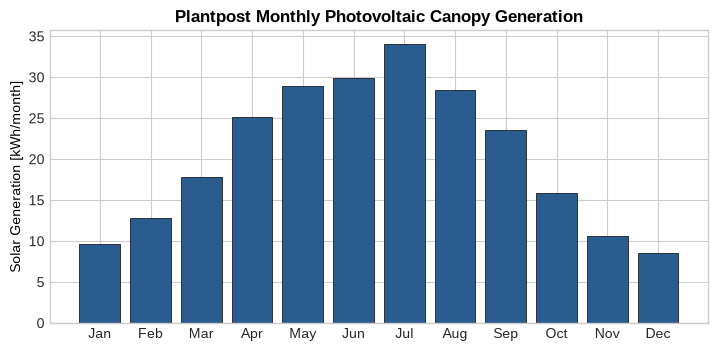

In [2]:
canopy = PhotovoltaicCanopy()
pv_power_w = canopy.calculate_power(df_w)
total_pv_kwh = pv_power_w.sum() / 1000.0
print(f'Annual PV Generation: {total_pv_kwh:.1f} kWh/yr')

monthly_pv_kwh = pv_power_w.groupby(df_w['month']).sum() / 1000.0
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.figure(figsize=(8.5, 3.8))
plt.bar(months, monthly_pv_kwh, color='#2b5c8f', edgecolor='#000000', lw=0.5)
plt.ylabel('Solar Generation [kWh/month]', color='#000000')
plt.title('Plantpost Monthly Photovoltaic Canopy Generation', fontweight='bold', color='#000000')
plt.show()

### 2. Public Lighting Schedule & Electrical Load
The luminaire consumes 7.1\text{ W}$ throughout civil night (when solar elevation $\le -6^\circ$).
A continuous auxiliary load of .5\text{ W}$ powers the BMS and microcontrollers.

In [3]:
light_power_w = canopy.calculate_lighting_load(df_w)
total_light_kwh = light_power_w.sum() / 1000.0
print(f'Annual Lighting Electricity Demand: {total_light_kwh:.1f} kWh/yr')
monthly_light_kwh = light_power_w.groupby(df_w['month']).sum() / 1000.0

df_balance = pd.DataFrame({
    'PV Generation [kWh]': monthly_pv_kwh.round(1),
    'Lighting Demand [kWh]': monthly_light_kwh.round(1),
    'Net Energy [kWh]': (monthly_pv_kwh - monthly_light_kwh).round(1)
}, index=months)
df_balance

Annual Lighting Electricity Demand: 184.7 kWh/yr


,PV Generation [kWh],Lighting Demand [kWh],Net Energy [kWh]
Jan,NaN,NaN,NaN
Feb,NaN,NaN,NaN
Mar,NaN,NaN,NaN
Apr,NaN,NaN,NaN
May,NaN,NaN,NaN
Jun,NaN,NaN,NaN
Jul,NaN,NaN,NaN
Aug,NaN,NaN,NaN
Sep,NaN,NaN,NaN
Oct,NaN,NaN,NaN


### 3. LiFePO4 Battery Storage Simulation & Solstice Stress Test
We simulate battery state-of-charge over all 8,760 hours across three capacity sizings:
- **0.80 kWh** (Under-sized budget pack)
- **1.28 kWh** (Nominal baseline: 100 Ah @ 12.8V)
- **2.00 kWh** (Resilient autonomy pack)

Capacity 0.8 kWh              | Reliability: 70.55% | LOLP: 0.294 | Unserved: 51.436 kWh
Capacity 1.28 kWh (Baseline)  | Reliability: 71.9% | LOLP: 0.281 | Unserved: 49.236 kWh
Capacity 2.0 kWh              | Reliability: 72.95% | LOLP: 0.271 | Unserved: 47.553 kWh


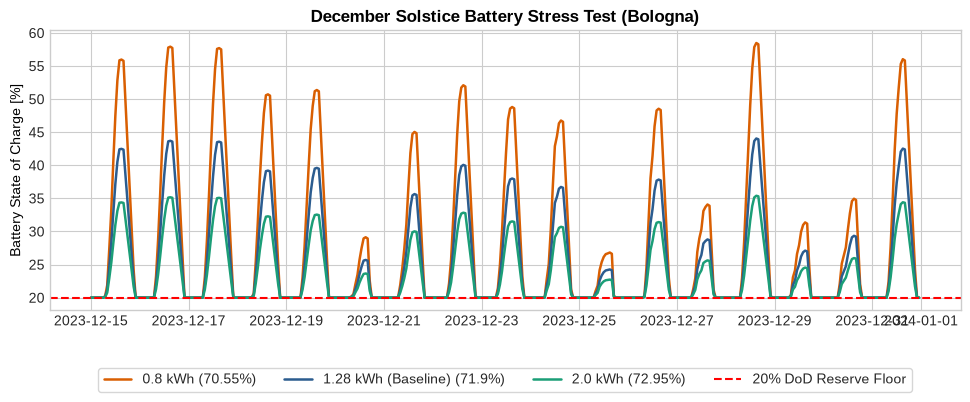

In [4]:
sim_results = {}
for cap, label in [(0.8, '0.8 kWh'), (1.28, '1.28 kWh (Baseline)'), (2.0, '2.0 kWh')]:
    bat_model = BatteryMicrogrid(capacity_kwh=cap)
    sim_df = bat_model.simulate(df_w, pv_power_w, light_power_w)
    metrics = bat_model.evaluate(sim_df)
    sim_results[label] = (metrics, sim_df)
    print(f'Capacity {label:<20} | Reliability: {metrics["electrical_reliability_pct"]}% | LOLP: {metrics["loss_of_load_probability_lolp"]:.3f} | Unserved: {metrics["total_unserved_kwh"]} kWh')

plt.figure(figsize=(10, 4.2))
dec_mask = df_w['datetime'] >= '2023-12-15 00:00:00'
times = df_w.loc[dec_mask, 'datetime']

colors = ['#d95f02', '#2b5c8f', '#1b9e77']
for (label, (m, sim)), c in zip(sim_results.items(), colors):
    soc = sim.loc[dec_mask, 'battery_soc'] * 100.0
    plt.plot(times, soc, label=f'{label} ({m["electrical_reliability_pct"]}%)', color=c, lw=1.8)

plt.axhline(20.0, color='red', linestyle='--', label='20% DoD Reserve Floor')
plt.ylabel('Battery State of Charge [%]', color='#000000')
plt.title('December Solstice Battery Stress Test (Bologna)', fontweight='bold', color='#000000')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=True)
plt.tight_layout()
plt.show()